# Assessment Task No. 6 — SMS Spam Classification with NLP and Multinomial Naive Bayes
**Course:** CSST102 – Basic Machine Learning  |  **Student Name:** Parreño, Leica Ricelle M.  |  **Section:** BSCS 3B

In [ ]:
import re, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Task 1 — Dataset Exploration and Analysis

In [ ]:
data = pd.read_csv("spam.csv", encoding="latin-1")
print("Dataset dimensions (rows, columns):", data.shape)
data.head(10)

Dataset dimensions (rows, columns): (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


In [ ]:
print("Missing values per column:")
print(data.isnull().sum())

Missing values per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


In [ ]:
# Remove the unnecessary columns and rename v1 -> class, v2 -> message
data = data.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"])
data = data.rename(columns={"v1": "class", "v2": "message"})

print("Duplicate messages:", data.duplicated().sum())
print("Shape after cleaning:", data.shape)
data.head(10)

Duplicate messages: 403
Shape after cleaning: (5572, 2)


,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [ ]:
counts = data["class"].value_counts()
percent = data["class"].value_counts(normalize=True) * 100
summary = pd.DataFrame({"Count": counts, "Percentage (%)": percent.round(2)})
print(summary)

       Count  Percentage (%)
class                       
ham     4825           86.59
spam     747           13.41


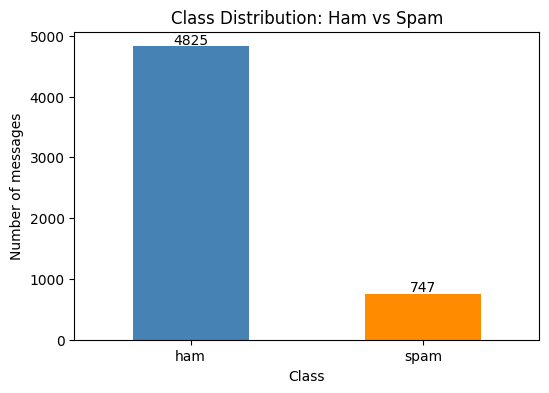

In [ ]:
ax = counts.plot(kind="bar", color=["steelblue", "darkorange"], figsize=(6, 4))
plt.title("Class Distribution: Ham vs Spam")
plt.xlabel("Class"); plt.ylabel("Number of messages")
plt.xticks(rotation=0)
for i, v in enumerate(counts):
    plt.text(i, v + 40, str(v), ha="center")
plt.show()

**Explain whether the dataset is balanced or imbalanced.**

The dataset is imbalanced. Most messages are ham (86.59%) and only a few are spam (13.41%). Because of this, accuracy alone isn’t enough, so I also checked precision, recall and F1-score for spam.

## Task 2 — NLP Text Preprocessing

In [ ]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    # 1. Convert to lowercase
    text = text.lower()
    # 2. Remove punctuation marks and special characters
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"[^a-z0-9\s]", " ", text)      # any remaining non-alphanumeric symbols
    # 3. Remove digits
    text = re.sub(r"\d+", "", text)
    # 4. Tokenization
    tokens = word_tokenize(text)
    # 5. Remove English stopwords
    tokens = [t for t in tokens if t not in stop_words]
    # 6. Stemming
    tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

data["clean_message"] = data["message"].apply(preprocess_text)

# Display five original messages next to their preprocessed versions
pd.set_option("display.max_colwidth", 120)
data[["message", "clean_message"]].head(5)

,message,clean_message
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go jurong point crazi avail bugi n great world la e buffet cine got amor wat
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entri wkli comp win fa cup final tkt st may text fa receiv entri questionstd txt ratetc appli over
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives around here though",nah dont think goe usf live around though


In [ ]:
# Some messages may become empty after cleaning (e.g. only digits/stopwords)
print("Empty messages after preprocessing:", (data["clean_message"].str.strip() == "").sum())

Empty messages after preprocessing: 6


**Analysis question: Explain how text preprocessing can affect the classification performance of
a Naive Bayes model.**

Preprocessing cleans the text so the model has fewer and better words to learn from. Lowercasing, removing punctuation and numbers, removing stopwords and stemming all group similar words together and remove extra noise. This helps the model make better predictions. But it can also remove useful clues, like numbers or capital letters, that spam often uses.

## Task 3 — Text Feature Extraction

In [ ]:
count_vec = CountVectorizer()
X_count = count_vec.fit_transform(data["clean_message"])

tfidf_vec = TfidfVectorizer()
X_tfidf = tfidf_vec.fit_transform(data["clean_message"])

print("=== CountVectorizer ===")
print("Feature matrix dimensions:", X_count.shape)
print("Vocabulary size:", len(count_vec.get_feature_names_out()))
print("10 example features:", list(count_vec.get_feature_names_out()[1000:1010]))

print("\n=== TfidfVectorizer ===")
print("Feature matrix dimensions:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf_vec.get_feature_names_out()))
print("10 example features:", list(tfidf_vec.get_feature_names_out()[1000:1010]))

=== CountVectorizer ===
Feature matrix dimensions: (5572, 7043)
Vocabulary size: 7043
10 example features: ['chick', 'chicken', 'chief', 'chik', 'chikku', 'chikkuali', 'chikkub', 'chikkudb', 'chikkugo', 'chikkuil']

=== TfidfVectorizer ===
Feature matrix dimensions: (5572, 7043)
Vocabulary size: 7043
10 example features: ['chick', 'chicken', 'chief', 'chik', 'chikku', 'chikkuali', 'chikkub', 'chikkudb', 'chikkugo', 'chikkuil']



**Analysis question: Explain the difference between word frequency and TF-IDF weighting.
Which representation might be more suitable for spam classification, and why?**

Word frequency just counts how many times a word appears. TF-IDF also gives less weight to words that appear in many messages and more weight to words that are rare. TF-IDF sounds better for spam, but Naive Bayes works well with counts, and in my results the count version did better.

## Task 4 — Naive Bayes Model Development

In [ ]:
X = data["clean_message"]
y = data["class"].map({"ham": 0, "spam": 1})   # spam = positive class

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

print("Training size:", len(X_train), " Testing size:", len(X_test))
print("Spam share  -> train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Training size: 3900  Testing size: 1672
Spam share  -> train: 0.134 | test: 0.134


In [ ]:
# ---------- Model A: CountVectorizer + Multinomial Naive Bayes ----------
vec_A = CountVectorizer()
X_train_A = vec_A.fit_transform(X_train)     # fit on TRAINING data only
X_test_A  = vec_A.transform(X_test)          # transform only (no leakage)
model_A = MultinomialNB()
model_A.fit(X_train_A, y_train)
pred_A = model_A.predict(X_test_A)

# ---------- Model B: TfidfVectorizer + Multinomial Naive Bayes ----------
vec_B = TfidfVectorizer()
X_train_B = vec_B.fit_transform(X_train)
X_test_B  = vec_B.transform(X_test)
model_B = MultinomialNB()
model_B.fit(X_train_B, y_train)
pred_B = model_B.predict(X_test_B)

print("Model A feature matrix (train):", X_train_A.shape)
print("Model B feature matrix (train):", X_train_B.shape)
print("First 10 test predictions -> A:", pred_A[:10], "| B:", pred_B[:10])

Model A feature matrix (train): (3900, 5849)
Model B feature matrix (train): (3900, 5849)
First 10 test predictions -> A: [1 0 1 0 0 0 0 0 0 0] | B: [1 0 1 0 0 0 0 0 0 0]


## Task 5 — Model Evaluation and Comparison

In [ ]:
def evaluate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),   # spam class
        "Recall":    recall_score(y_true, y_pred),      # spam class
        "F1-score":  f1_score(y_true, y_pred),          # spam class
        "False Positives": fp,
        "False Negatives": fn,
    }

results = pd.DataFrame({"Model A (Count + MNB)": evaluate(y_test, pred_A),
                        "Model B (TF-IDF + MNB)": evaluate(y_test, pred_B)})
results.index.name = "Evaluation Metric"
results.round(4)

,Model A (Count + MNB),Model B (TF-IDF + MNB)
Evaluation Metric,,
Accuracy,0.9779,0.9623
Precision,0.9390,0.9939
Recall,0.8929,0.7232
F1-score,0.9153,0.8372
False Positives,13.0000,1.0000
False Negatives,24.0000,62.0000


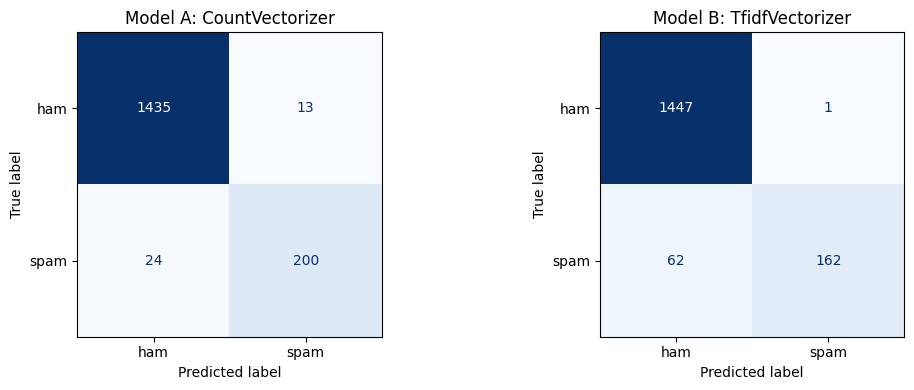

Model A
               precision    recall  f1-score   support

         ham       0.98      0.99      0.99      1448
        spam       0.94      0.89      0.92       224

    accuracy                           0.98      1672
   macro avg       0.96      0.94      0.95      1672
weighted avg       0.98      0.98      0.98      1672

Model B
               precision    recall  f1-score   support

         ham       0.96      1.00      0.98      1448
        spam       0.99      0.72      0.84       224

    accuracy                           0.96      1672
   macro avg       0.98      0.86      0.91      1672
weighted avg       0.96      0.96      0.96      1672



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in zip(axes, [pred_A, pred_B],
                           ["Model A: CountVectorizer", "Model B: TfidfVectorizer"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

print("Model A\n", classification_report(y_test, pred_A, target_names=["ham", "spam"]))
print("Model B\n", classification_report(y_test, pred_B, target_names=["ham", "spam"]))

In [ ]:
best_name = "A" if f1_score(y_test, pred_A) >= f1_score(y_test, pred_B) else "B"
print("Better model by spam F1-score: Model", best_name)

Better model by spam F1-score: Model A


**Analysis question: Which model performs better? Explain why precision and recall are
important for spam detection, particularly when legitimate messages may be incorrectly
classified as spam.**

Model A (CountVectorizer) is better overall, with higher accuracy (97.79%), recall (89.29%) and F1-score (0.9153). Model B had higher precision (99.39%) but missed 62 spam messages, compared with 24 for Model A.

Low precision means real messages get sent to the spam folder, and low recall means spam reaches the inbox. Model A balances the two better.

## Task 6 — Testing with Unseen Messages

In [ ]:
# Use the better-performing model (chosen automatically from Task 5)
best_vec, best_model = (vec_A, model_A) if best_name == "A" else (vec_B, model_B)

new_messages = [
    "Congratulations! You have won a free cash prize.",
    "Good morning, our class starts at 8 AM tomorrow.",
    "Claim your reward now by clicking this link.",
    "Please submit your assignment before Friday.",
    "URGENT! You have been selected to receive a cash bonus.",
]

cleaned = [preprocess_text(m) for m in new_messages]
features = best_vec.transform(cleaned)          # transform only, never fit
labels = best_model.predict(features)
probs = best_model.predict_proba(features)      # columns: [P(ham), P(spam)]

out = pd.DataFrame({
    "No.": range(1, 6),
    "SMS Message": new_messages,
    "Prediction": ["spam" if l == 1 else "ham" for l in labels],
    "P(ham)": probs[:, 0].round(4),
    "P(spam)": probs[:, 1].round(4),
})
print("Using Model", best_name)
out

Using Model A


,No.,SMS Message,Prediction,P(ham),P(spam)
0,1,Congratulations! You have won a free cash prize.,spam,0.0001,0.9999
1,2,"Good morning, our class starts at 8 AM tomorrow.",ham,1.0000,0.0000
2,3,Claim your reward now by clicking this link.,spam,0.0002,0.9998
3,4,Please submit your assignment before Friday.,ham,0.9245,0.0755
4,5,URGENT! You have been selected to receive a cash bonus.,spam,0.0000,1.0000


**Analysis question: Identify any unexpected predictions and explain possible reasons for the
model's behavior.**

All five predictions were as expected. Message 4 (“Please submit your assignment before Friday”) was ham but with lower confidence (92.45%). Words like “assignment” are probably rare in this older SMS dataset, and Naive Bayes treats each word separately, so a single word can slightly raise the spam probability.